# 07 · Model Evaluation
**Milestone 6 — Kenyan Retail Customer & Sales Intelligence Capstone**

This notebook evaluates the models chosen in notebook 06 on **data they have never seen**. It then produces the two
business outputs:

1. **The January 2026 revenue forecast**, with an uncertainty range (chain and stores).
2. **The current list of at-risk customers** as of 31 December 2025.

All model choices are loaded from `reports/model_selection.json`, so nothing here is tuned on test data.

In [1]:
# --- Setup: make the project's "src" package importable from this notebook ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import style

style.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
import json
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_score, recall_score, f1_score, confusion_matrix
from src.analysis import eda
import seaborn as sns
from src.modeling import forecasting as fc, churn as ch, metrics as mt

selection = json.loads((config.REPORTS_DIR / "model_selection.json").read_text())
print(json.dumps(selection, indent=2))
sales = eda.load_analytical()
store_month = fc.monthly_store_revenue(sales)
chain = store_month.groupby("month")["revenue"].sum()
metrics_log = []

{
  "forecast_model": "Holt exponential smoothing",
  "rf_params": {
    "n_estimators": 300,
    "max_depth": 3,
    "min_samples_leaf": 1
  },
  "holt_damped": true,
  "selection_metric": "validation MAE (Jan-Jun 2025, walk-forward)",
  "churn_model": "Baseline: recency only",
  "inactivity_threshold_days": 180
}


# Part A: Forecast evaluation on the test period (Jul–Dec 2025)

In [3]:
test_preds, test_store = fc.walk_forward(store_month, fc.TEST_MONTHS, selection["rf_params"], selection["holt_damped"])
val_preds = pd.read_csv(config.PROCESSED_DIR / "forecast_validation_predictions.csv", index_col="month", parse_dates=True)
val_preds = val_preds.drop(columns=["Holt (undamped trend)"])

test_scores = mt.score_table(test_preds)
val_scores = mt.score_table(val_preds)
comparison = (val_scores.set_index("model")[["MAE", "MAPE_%"]].add_prefix("validation_")
              .join(test_scores.set_index("model")[["MAE", "RMSE", "MAPE_%"]].add_prefix("test_"))
              .sort_values("test_MAE"))
for model, r in comparison.iterrows():
    metrics_log.append({"model_type": "forecast (chain)", "model": model, "validation_MAE": r["validation_MAE"],
                        "test_MAE": r["test_MAE"], "test_RMSE": r["test_RMSE"], "test_MAPE_%": r["test_MAPE_%"]})
comparison.round(1)

,validation_MAE,validation_MAPE_%,test_MAE,test_RMSE,test_MAPE_%
model,,,,,
Holt exponential smoothing,"10,563.80",11.90,"17,500.00","22,816.90",16.50
Random Forest (store panel),"10,780.90",13.20,"17,677.50","20,870.30",17.80
Naive (last month),"15,762.70",19.60,"18,447.90","25,861.20",17.50
Moving average (3 months),"13,928.60",15.90,"20,328.40","26,253.70",20.00
Seasonal naive (last year),"16,194.30",17.30,"23,610.00","26,818.60",23.80


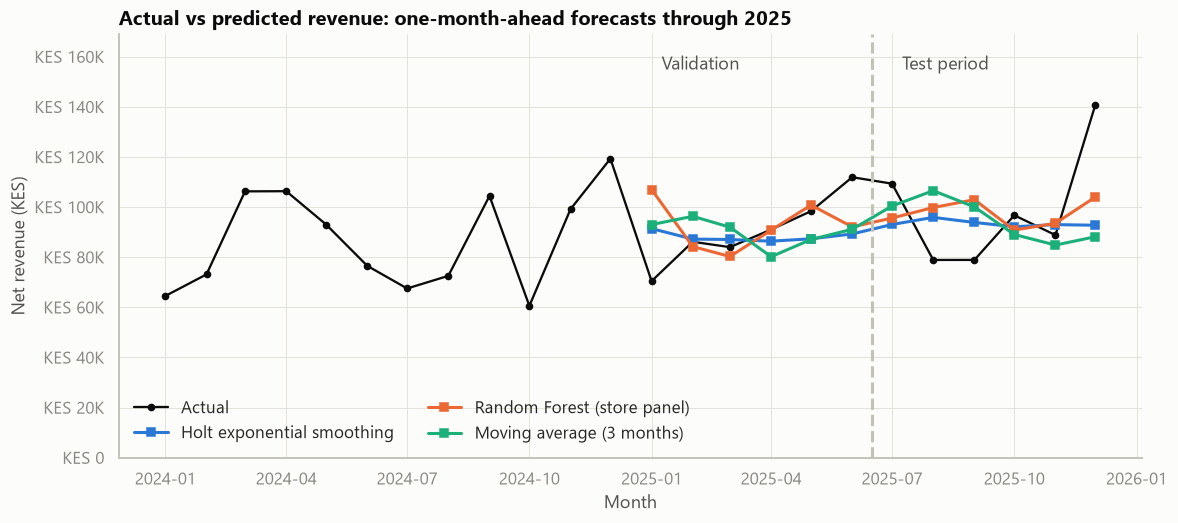

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(chain.index, chain.values, color=style.INK["primary"], marker="o", markersize=4, linewidth=1.5, label="Actual")
both = pd.concat([val_preds, test_preds])
for name, colour in [("Holt exponential smoothing", style.SERIES[0]), ("Random Forest (store panel)", style.SERIES[1]),
                     ("Moving average (3 months)", style.SERIES[2])]:
    ax.plot(both.index, both[name], marker="s", markersize=5, color=colour, label=name)
ax.axvline(fc.TEST_MONTHS[0] - pd.Timedelta(days=15), color=style.INK["axis"], linestyle="--")
ax.text(fc.TEST_MONTHS[0], chain.max() * 1.1, "  Test period", color=style.INK["secondary"])
ax.text(fc.VALIDATION_MONTHS[0], chain.max() * 1.1, "  Validation", color=style.INK["secondary"])
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_ylim(0, chain.max() * 1.2)
ax.set_title("Actual vs predicted revenue: one-month-ahead forecasts through 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (KES)")
ax.legend(loc="lower left", ncol=2)
style.save(fig, "m7_actual_vs_predicted")
plt.show()

### Does the selected model generalize to unseen months?
The cell below compares the selected model with the best baseline on the test months, and validation error with test error.

In [5]:
chosen = selection["forecast_model"]
baselines = ["Naive (last month)", "Seasonal naive (last year)", "Moving average (3 months)"]
best_base = comparison.loc[baselines, "test_MAE"].idxmin()
chosen_mae, base_mae = comparison.loc[chosen, "test_MAE"], comparison.loc[best_base, "test_MAE"]
print(f"Selected model ({chosen}): test MAE KES {chosen_mae:,.0f}, MAPE {comparison.loc[chosen, 'test_MAPE_%']:.1f}%")
print(f"Best baseline on test ({best_base}): MAE KES {base_mae:,.0f}")
print(f"Improvement over best baseline: {1 - chosen_mae / base_mae:+.0%}")
print(f"Generalization: validation MAE KES {comparison.loc[chosen, 'validation_MAE']:,.0f} -> test MAE KES {chosen_mae:,.0f}")

errors = pd.concat([val_preds, test_preds])
errors = (errors["actual"] - errors[chosen]).rename("error")
print(f"\nMean error over the 12 walk-forward months (bias): KES {errors.mean():,.0f} "
      f"({'under' if errors.mean() > 0 else 'over'}-forecasting on average)")
display(test_preds[["actual", chosen, "Random Forest (store panel)", best_base]].round(0))

Selected model (Holt exponential smoothing): test MAE KES 17,500, MAPE 16.5%
Best baseline on test (Naive (last month)): MAE KES 18,448
Improvement over best baseline: +5%
Generalization: validation MAE KES 10,564 -> test MAE KES 17,500

Mean error over the 12 walk-forward months (bias): KES 3,835 (under-forecasting on average)


,actual,Holt exponential smoothing,Random Forest (store panel),Naive (last month)
month,,,,
2025-07-01,"109,353.00","93,062.00","95,636.00","111,928.00"
2025-08-01,"78,915.00","95,899.00","99,833.00","109,353.00"
2025-09-01,"78,927.00","93,876.00","102,964.00","78,915.00"
2025-10-01,"96,734.00","92,172.00","90,825.00","78,927.00"
2025-11-01,"88,843.00","93,013.00","93,545.00","96,734.00"
2025-12-01,"140,808.00","92,765.00","104,026.00","88,843.00"


### Residual analysis: when does the model miss?

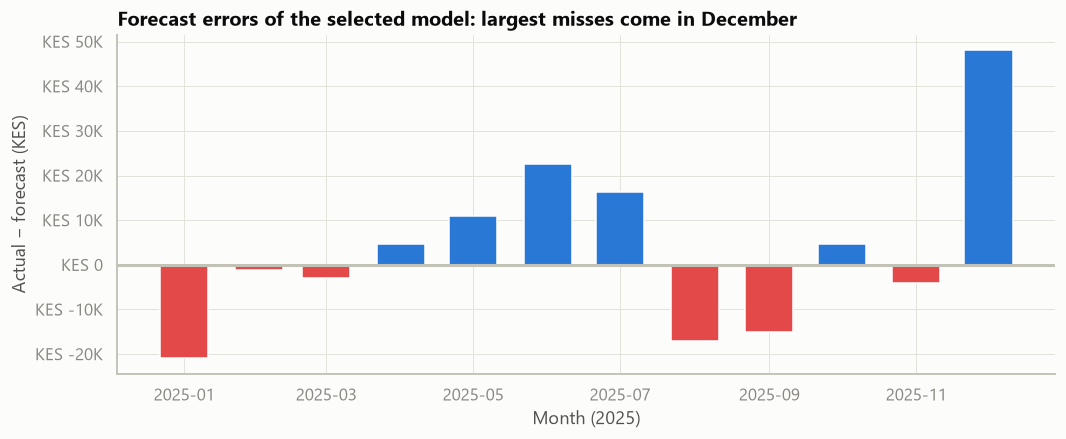

month
2025-01-01   -20,957.00
2025-02-01    -1,075.00
2025-03-01    -3,047.00
2025-04-01     4,641.00
2025-05-01    11,021.00
2025-06-01    22,643.00
2025-07-01    16,291.00
2025-08-01   -16,984.00
2025-09-01   -14,949.00
2025-10-01     4,562.00
2025-11-01    -4,171.00
2025-12-01    48,043.00


In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
colors = [style.SERIES[0] if e >= 0 else style.SERIES[7] for e in errors]
ax.bar(errors.index, errors.values, width=20, color=colors)
ax.axhline(0, color=style.INK["axis"])
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_title("Forecast errors of the selected model: largest misses come in December")
ax.set_xlabel("Month (2025)")
ax.set_ylabel("Actual − forecast (KES)")
style.save(fig, "m7_residuals")
plt.show()
print(errors.round(0).to_string())

**Interpretation of the test results:**
- **Holt still ranks first on the test period, but only narrowly.** Test MAE is KES 17,500 (16.5%), against KES 18,400
  for the naive baseline (+5%) and KES 17,700 for the Random Forest. With only 6 test months, a 5% difference is **not
  conclusive**. The honest summary is that Holt is *at least as good as* the simple baselines, not clearly better.
- **Error grew from validation (KES 10,600) to test (KES 17,500).** Most of the increase is **December 2025**, which was
  under-forecast by KES 48,000. Holt forecasts an almost flat line of about KES 93,000, because it models level and trend
  but **no seasonality**, so it cannot anticipate the December peak.
  - The residuals confirm this: the largest misses are the December peak (actual far above the forecast) and January
    2025 (actual far below).
- **Bias:** over the 12 walk-forward months the model under-forecast by about KES 3,800 a month on average. That is
  small next to the size of individual misses.

**Business meaning:** the model gives a sound estimate of the *underlying monthly level* (about KES 90–100K), but
management must add their own **seasonal judgement**: more for December, less for January. A seasonal model becomes
possible once at least three years of history exist.

### Store-level forecasts (secondary)

In [7]:
store_scores = mt.score_table(test_store[["actual", "Naive (last month)", "Random Forest (store panel)"]])
display(store_scores.round(1))
for _, r in store_scores.iterrows():
    metrics_log.append({"model_type": "forecast (store-month)", "model": r["model"], "test_MAE": r["MAE"],
                        "test_RMSE": r["RMSE"], "test_MAPE_%": r["MAPE_%"]})
by_store = (test_store.assign(abs_err=lambda d: (d["actual"] - d["Random Forest (store panel)"]).abs())
            .groupby("town")[["actual", "abs_err"]].mean())
by_store["MAPE_%"] = test_store.groupby("town").apply(
    lambda d: mt.mape(d["actual"], d["Random Forest (store panel)"]))
by_store.round(0)

,model,MAE,RMSE,MAPE_%
0,Random Forest (store panel),"6,444.40","8,449.20",50.90
1,Naive (last month),"7,485.20","10,386.60",48.60


,actual,abs_err,MAPE_%
town,,,
Kisumu Town,"15,901.00","7,363.00",36.00
Mombasa Town,"14,780.00","3,278.00",19.00
Nairobi CBD,"23,481.00","8,540.00",39.00
Nakuru Town,"17,366.00","5,741.00",35.00
Thika,"10,647.00","7,714.00",136.00
Westlands,"16,755.00","6,031.00",40.00


**Store-level results:** store-month revenue is far noisier than the chain total, so percentage errors per store are
large. A single TV or smartphone sale can be 20–40% of a store's month. Store forecasts should be used as **rough
planning guides**, not targets. The chain forecast is the reliable number.

## A.2 The January 2026 forecast, with uncertainty

In [8]:
point, all_models, rf_store = fc.forecast_next_month(store_month, chosen, selection["rf_params"], selection["holt_damped"])

# Uncertainty from the model's OWN out-of-sample errors (12 walk-forward months).
# Empirical interval: 10th-90th percentile of errors -> 80% range.
# Normal approximation: +/- 1.96 x RMSE -> approximate 95% range.
low80, high80 = point + np.percentile(errors, 10), point + np.percentile(errors, 90)
rmse_all = np.sqrt(np.mean(errors ** 2))
low95, high95 = point - 1.96 * rmse_all, point + 1.96 * rmse_all
jan_2025 = chain.loc["2025-01-01"]

print(f"January 2026 chain revenue forecast ({chosen}): KES {point:,.0f}")
print(f"  80% range (empirical): KES {low80:,.0f} to {high80:,.0f}")
print(f"  95% range (±1.96 RMSE): KES {low95:,.0f} to {high95:,.0f}")
print(f"  For reference, January 2025 actual: KES {jan_2025:,.0f}; December 2025 actual: KES {chain.iloc[-1]:,.0f}")
print("\nAll models' January 2026 forecasts (transparency):")
print(pd.Series(all_models).map("KES {:,.0f}".format).to_string())

January 2026 chain revenue forecast (Holt exponential smoothing): KES 98,788
  80% range (empirical): KES 82,007 to 120,796
  95% range (±1.96 RMSE): KES 61,993 to 135,582
  For reference, January 2025 actual: KES 70,471; December 2025 actual: KES 140,808

All models' January 2026 forecasts (transparency):
Naive (last month)             KES 140,808
Seasonal naive (last year)      KES 70,471
Moving average (3 months)      KES 108,795
Holt exponential smoothing      KES 98,788
Random Forest (store panel)    KES 123,858


### Seasonal scenario for January (a judgement aid, NOT a validated model)

Holt has no seasonality, but January is reliably the weakest month: it was the lowest or second-lowest month in both
years. As a **scenario**, the Holt level is scaled by the average ratio of January revenue to the average month in the
two observed years.

This ratio was *not* selected or tested on the validation data. It is based on just two Januaries and is shown only to
inform management's judgement.

In [9]:
monthly_mean_by_year = chain.groupby(chain.index.year).mean()
jan_ratio = np.mean([chain.loc[f"{y}-01-01"] / monthly_mean_by_year[y] for y in (2024, 2025)])
scenario = point * jan_ratio
print(f"January revenue vs the average month: {jan_ratio:.2f} (average of 2024 and 2025)")
print(f"Seasonal scenario for January 2026: KES {scenario:,.0f}  (Holt level KES {point:,.0f} x {jan_ratio:.2f})")
print(f"Previous Januaries: 2024 KES {chain.loc['2024-01-01']:,.0f}; 2025 KES {chain.loc['2025-01-01']:,.0f}")

January revenue vs the average month: 0.74 (average of 2024 and 2025)
Seasonal scenario for January 2026: KES 73,442  (Holt level KES 98,788 x 0.74)
Previous Januaries: 2024 KES 64,546; 2025 KES 70,471


**Recommendation for January 2026 planning:**
- The model's point forecast is **about KES 99K**, with an 80% range of **KES 82K–121K**.
- The past two Januaries (KES 64.5K and KES 70.5K) both fell *below* that range, and the seasonal scenario is about
  **KES 73K**.
- Management should therefore **plan stock and cash for the lower part of the range (about KES 75–85K)** and treat the
  Holt point forecast as an upper-middle case.
- This illustrates the model's main limitation: no seasonality.

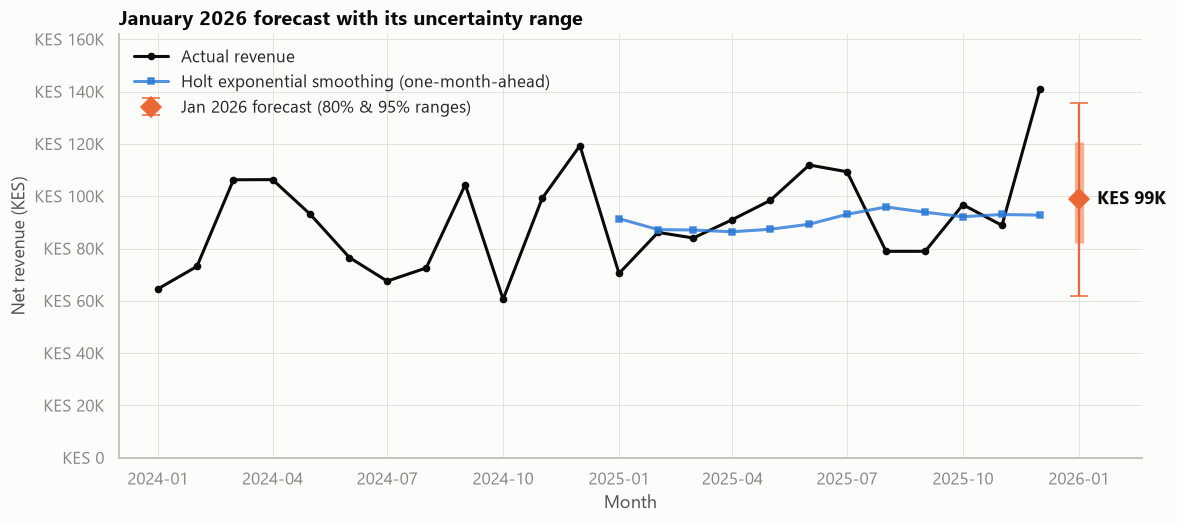

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(chain.index, chain.values, color=style.INK["primary"], marker="o", markersize=4, label="Actual revenue")
ax.plot(both.index, both[chosen], color=style.SERIES[0], marker="s", markersize=4, alpha=0.8,
        label=f"{chosen} (one-month-ahead)")
ax.errorbar([fc.NEXT_MONTH], [point], yerr=[[point - low80], [high80 - point]], fmt="D", color=style.SERIES[1],
            ecolor=style.SERIES[1], elinewidth=6, alpha=0.5, capsize=0)
ax.errorbar([fc.NEXT_MONTH], [point], yerr=[[point - low95], [high95 - point]], fmt="D", color=style.SERIES[1],
            ecolor=style.SERIES[1], elinewidth=1.5, capsize=6, markersize=9, label="Jan 2026 forecast (80% & 95% ranges)")
ax.annotate(f"KES {point/1000:,.0f}K", (fc.NEXT_MONTH, point), xytext=(12, 0), textcoords="offset points",
            color=style.INK["primary"], fontweight="bold", va="center")
ax.yaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_ylim(0, max(chain.max(), high95) * 1.15)
ax.set_xlim(pd.Timestamp("2023-12-01"), pd.Timestamp("2026-02-20"))
ax.set_title("January 2026 forecast with its uncertainty range")
ax.set_xlabel("Month")
ax.set_ylabel("Net revenue (KES)")
ax.legend(loc="upper left")
style.save(fig, "m7_forecast_jan2026")
plt.show()

In [11]:
# Store-level January 2026 view: the Random Forest's store forecasts, rescaled so they add up
# to the chain forecast (keeps one consistent total for management).
store_jan = (rf_store / rf_store.sum() * point).rename("forecast_kes").to_frame()
store_jan["share_of_chain"] = store_jan["forecast_kes"] / point
store_jan["jan_2025_actual"] = store_month[store_month["month"] == "2025-01-01"].set_index("town")["revenue"]
store_jan = store_jan.sort_values("forecast_kes", ascending=False)

# Save outputs for the Power BI forecast page
history = chain.rename("actual").to_frame()
history["split"] = np.where(history.index <= fc.TRAIN_END, "train",
                            np.where(history.index.isin(fc.VALIDATION_MONTHS), "validation", "test"))
history = history.join(both.drop(columns="actual"))
future = pd.DataFrame({"actual": [np.nan], "split": ["forecast"], chosen: [point], "lower_80": [low80],
                       "upper_80": [high80], "lower_95": [low95], "upper_95": [high95],
                       "seasonal_scenario": [scenario]}, index=[fc.NEXT_MONTH])
forecast_out = pd.concat([history, future])
forecast_out.index.name = "month"
forecast_out.to_csv(config.PROCESSED_DIR / "forecast_monthly.csv")
store_jan.rename_axis("town").to_csv(config.PROCESSED_DIR / "forecast_jan2026_by_store.csv")
print("Saved data/processed/forecast_monthly.csv and forecast_jan2026_by_store.csv")
store_jan.round(2)

Saved data/processed/forecast_monthly.csv and forecast_jan2026_by_store.csv


,forecast_kes,share_of_chain,jan_2025_actual
Nairobi CBD,"17,985.57",0.18,"22,039.70"
Westlands,"17,524.67",0.18,"13,575.50"
Nakuru Town,"16,391.70",0.17,"11,518.30"
Mombasa Town,"15,671.18",0.16,"9,401.80"
Kisumu Town,"15,657.06",0.16,"7,771.00"
Thika,"15,557.61",0.16,"6,165.00"


**Store split caution:** the Random Forest's store forecasts are rescaled to add up to the chain forecast.
- They come out **very even** (about 16–18% each), because with so little data the model pulls every store towards the average.
- Store-month errors on the test period were about 50% (MAPE). Thika's was 136%, driven by one KES 26K month.
- Use these figures as a rough allocation guide only. For store targets, last year's store shares are equally defensible.

# Part B: At-risk customer model on the out-of-time test snapshot

**Test set:** established customers as of **30 June 2025**, with features from orders up to that date. The label is
whether they **bought again in Jul–Dec 2025**. All models were fitted on the 31 December 2024 snapshot.

In [12]:
train = ch.add_churn_label(ch.customer_features(sales, ch.TRAIN_SNAPSHOT), sales, ch.TRAIN_SNAPSHOT)
test = ch.add_churn_label(ch.customer_features(sales, ch.TEST_SNAPSHOT), sales, ch.TEST_SNAPSHOT)
X_tr, y_tr, X_te, y_te = train[ch.FEATURES], train["churned"], test[ch.FEATURES], test["churned"]

lr = ch.logistic_model().fit(X_tr, y_tr)
rf = ch.random_forest_model().fit(X_tr, y_tr)
scores_test = {"Recency rule (selected)": X_te["recency_days"].to_numpy(),
               "Logistic regression": lr.predict_proba(X_te)[:, 1],
               "Random Forest classifier": rf.predict_proba(X_te)[:, 1]}
scores_train = {"Recency rule (selected)": X_tr["recency_days"].to_numpy(),
                "Logistic regression": lr.predict_proba(X_tr)[:, 1],
                "Random Forest classifier": rf.predict_proba(X_tr)[:, 1]}
labels_test = {"Recency rule (selected)": ch.baseline_rule(test),
               "Logistic regression": (scores_test["Logistic regression"] >= 0.5).astype(int),
               "Random Forest classifier": (scores_test["Random Forest classifier"] >= 0.5).astype(int)}

def bootstrap_auc(y, s, n=2000, seed=42):
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            vals.append(roc_auc_score(y[idx], s[idx]))
    return np.percentile(vals, [2.5, 97.5])

rows = []
for name in scores_test:
    lo, hi = bootstrap_auc(y_te, scores_test[name])
    pred = labels_test[name]
    rows.append({"model": name, "train_AUC": roc_auc_score(y_tr, scores_train[name]),
                 "test_AUC": roc_auc_score(y_te, scores_test[name]), "test_AUC_95CI": f"{lo:.2f}–{hi:.2f}",
                 "test_PR_AUC": average_precision_score(y_te, scores_test[name]),
                 "precision": precision_score(y_te, pred), "recall": recall_score(y_te, pred),
                 "F1": f1_score(y_te, pred)})
churn_eval = pd.DataFrame(rows)
for _, r in churn_eval.iterrows():
    metrics_log.append({"model_type": "churn (out-of-time test)", "model": r["model"], "train_AUC": r["train_AUC"],
                        "test_AUC": r["test_AUC"], "precision": r["precision"], "recall": r["recall"], "F1": r["F1"]})
print(f"Test snapshot: {len(test)} customers, {y_te.mean():.1%} churned (did not return in Jul–Dec 2025)")
churn_eval.round(3)

Test snapshot: 308 customers, 80.5% churned (did not return in Jul–Dec 2025)


,model,train_AUC,test_AUC,test_AUC_95CI,test_PR_AUC,precision,recall,F1
0,Recency rule (selected),0.75,0.80,0.73–0.85,0.94,0.93,0.67,0.78
1,Logistic regression,0.81,0.83,0.78–0.88,0.95,0.90,0.81,0.85
2,Random Forest classifier,0.96,0.82,0.76–0.87,0.94,0.87,0.92,0.90


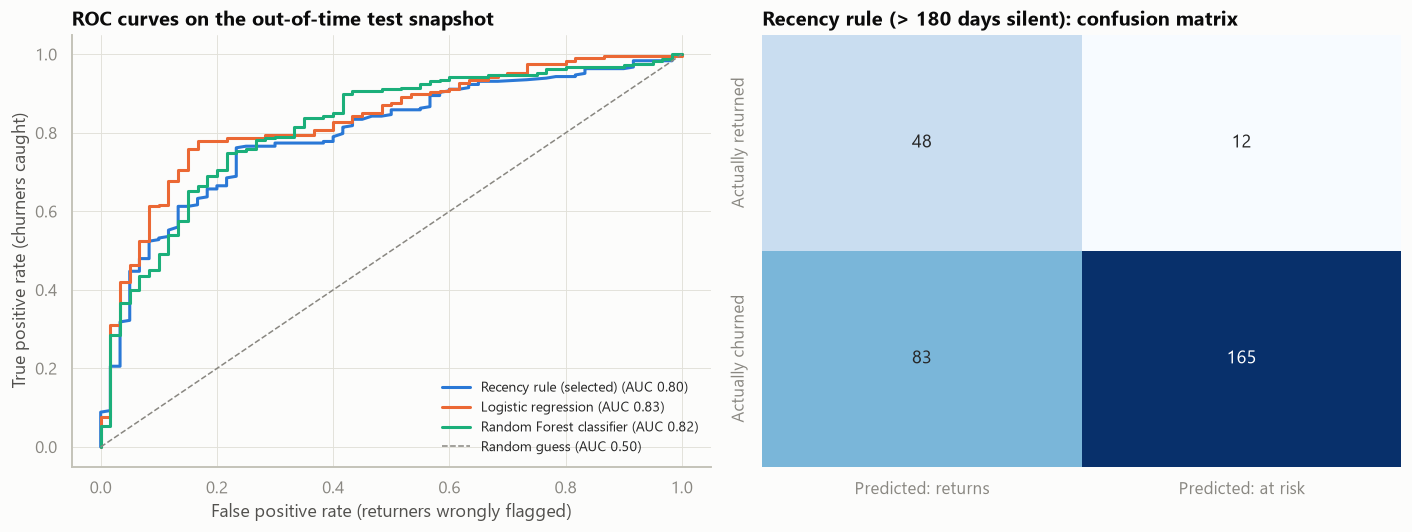

AUC difference, logistic regression minus recency rule: +0.037 (95% bootstrap CI +0.002 to +0.073)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (name, s), colour in zip(scores_test.items(), [style.SERIES[0], style.SERIES[1], style.SERIES[2]]):
    fpr, tpr, _ = roc_curve(y_te, s)
    axes[0].plot(fpr, tpr, color=colour, label=f"{name} (AUC {roc_auc_score(y_te, s):.2f})")
axes[0].plot([0, 1], [0, 1], color=style.NEUTRAL, linestyle="--", linewidth=1, label="Random guess (AUC 0.50)")
axes[0].set_title("ROC curves on the out-of-time test snapshot")
axes[0].set_xlabel("False positive rate (returners wrongly flagged)")
axes[0].set_ylabel("True positive rate (churners caught)")
axes[0].legend(loc="lower right", fontsize=9)

cm = confusion_matrix(y_te, labels_test["Recency rule (selected)"])
sns.heatmap(cm, annot=True, fmt="d", cmap=style.SEQUENTIAL, cbar=False, ax=axes[1],
            xticklabels=["Predicted: returns", "Predicted: at risk"], yticklabels=["Actually returned", "Actually churned"])
axes[1].set_title("Recency rule (> 180 days silent): confusion matrix")
fig.tight_layout()
style.save(fig, "m7_churn_roc_confusion")
plt.show()

d_lr = roc_auc_score(y_te, scores_test["Logistic regression"]) - roc_auc_score(y_te, scores_test["Recency rule (selected)"])
rng = np.random.default_rng(1)
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y_te), len(y_te))
    yy = y_te.to_numpy()[idx]
    if yy.min() != yy.max():
        diffs.append(roc_auc_score(yy, scores_test["Logistic regression"][idx]) -
                     roc_auc_score(yy, scores_test["Recency rule (selected)"][idx]))
print(f"AUC difference, logistic regression minus recency rule: {d_lr:+.3f} "
      f"(95% bootstrap CI {np.percentile(diffs, 2.5):+.3f} to {np.percentile(diffs, 97.5):+.3f})")

### Interpreting the churn evaluation
The cell below states the conclusions from the numbers above.

In [14]:
rule = churn_eval.set_index("model").loc["Recency rule (selected)"]
tn, fp, fn, tp = confusion_matrix(y_te, labels_test["Recency rule (selected)"]).ravel()
print(f"Recency rule on unseen customers: AUC {rule['test_AUC']:.2f}; of the {tp + fp} customers it flags, "
      f"{rule['precision']:.0%} really did not return (precision). It catches {rule['recall']:.0%} of all churners (recall).")
print(f"It wrongly flags {fp} of the {tn + fp} customers who did return, and misses {fn} churners who were silent < 180 days.")

Recency rule on unseen customers: AUC 0.80; of the 177 customers it flags, 93% really did not return (precision). It catches 67% of all churners (recall).
It wrongly flags 12 of the 60 customers who did return, and misses 83 churners who were silent < 180 days.


**Conclusions:**
- **All approaches generalize to the later period.** Test AUCs are 0.80 (rule), 0.83 (logistic regression) and 0.82
  (Random Forest), none worse than the training-period estimates.
  - The **Random Forest overfits**: training AUC 0.96 falls to 0.82 on test. That is the pattern the
    one-standard-error rule was designed to avoid.
- **The recency rule (selected) is precise but misses quiet churners.**
  - Of the 177 customers it flags, **93% genuinely did not return** (precision).
  - It catches 67% of churners (recall), missing 83 who had been silent for less than 180 days.
  - It wrongly flagged 12 customers who did come back.
- **Logistic regression ranks unseen customers better.** AUC is +0.037 higher, with a 95% bootstrap interval of
  **+0.002 to +0.073**, which excludes zero. Recall is also higher (0.81 against 0.67), at slightly lower precision (0.90).
  - It is therefore **modestly but genuinely better** on this test period. The cross-validation on the earlier snapshot
    could not detect this, because only 33 customers returned in that window.

**Decision:**
- The **recency rule remains the operational at-risk flag**. It was selected before testing, it is transparent, and
  it is highly precise.
- **Logistic regression is used as the priority score** for ranking customers within and outside the flagged group.
- **Re-run the model selection when the next 6 months of data arrive.** If logistic regression keeps its advantage, it
  should become the primary model.

This is a defensible process. Changing the choice now, *because* of the test result, would leak test information
into model selection.

## B.2 The current at-risk customer list (as of 31 December 2025)

- **Rule:** an established customer (2+ orders) with **no purchase for more than 180 days**.
- **Ordering:** by **value at risk** (lifetime spend), so the most valuable relationships are contacted first.
- **Supplementary model score:** a logistic regression refitted on the 30 June 2025 snapshot, whose outcome is now
  fully known. It ranks *all* established customers by churn probability.

In [15]:
current = ch.customer_features(sales, ch.SCORE_SNAPSHOT)
current["at_risk_rule"] = ch.baseline_rule(current)
scorer = ch.logistic_model().fit(test[ch.FEATURES], test["churned"])     # latest labelled snapshot
current["model_churn_probability"] = scorer.predict_proba(current[ch.FEATURES])[:, 1]
current["risk_band"] = pd.cut(current["model_churn_probability"], [0, 0.5, 0.75, 1.0],
                              labels=["Low", "Medium", "High"], include_lowest=True)

customers = pd.read_csv(config.CLEANED_DIR / "customers.csv")
stores = pd.read_csv(config.CLEANED_DIR / "stores.csv")
current = (current.merge(customers[["customer_id", "preferred_store_id"]], on="customer_id")
           .merge(stores[["store_id", "town"]].rename(columns={"store_id": "preferred_store_id", "town": "preferred_store"}),
                  on="preferred_store_id"))
out_cols = ["customer_id", "preferred_store", "frequency", "monetary_kes", "last", "recency_days", "avg_gap_days",
            "loyalty_member", "at_risk_rule", "model_churn_probability", "risk_band"]
risk = current[out_cols].rename(columns={"last": "last_purchase", "frequency": "orders", "monetary_kes": "lifetime_spend_kes"})
risk.sort_values(["at_risk_rule", "lifetime_spend_kes"], ascending=[False, False]).to_csv(
    config.PROCESSED_DIR / "customer_risk_scores.csv", index=False, date_format="%Y-%m-%d")

at_risk = risk[risk["at_risk_rule"] == 1]
print(f"Established customers: {len(risk)}; at risk (silent > 180 days): {len(at_risk)} ({len(at_risk)/len(risk):.0%}); "
      f"their lifetime spend: KES {at_risk['lifetime_spend_kes'].sum():,.0f}")
print(f"Not yet past 180 days but model probability >= 0.75 (early-warning group): "
      f"{((risk['at_risk_rule'] == 0) & (risk['model_churn_probability'] >= 0.75)).sum()}")
display(at_risk.groupby("preferred_store").agg(at_risk_customers=("customer_id", "size"),
                                               value_at_risk_kes=("lifetime_spend_kes", "sum"))
        .sort_values("value_at_risk_kes", ascending=False).round(0))
print("Top 15 at-risk customers by value at risk:")
at_risk.nlargest(15, "lifetime_spend_kes").round({"lifetime_spend_kes": 0, "avg_gap_days": 1, "model_churn_probability": 2})

Established customers: 419; at risk (silent > 180 days): 249 (59%); their lifetime spend: KES 541,641
Not yet past 180 days but model probability >= 0.75 (early-warning group): 3


,at_risk_customers,value_at_risk_kes
preferred_store,,
Nairobi CBD,64,"159,914.00"
Westlands,39,"87,892.00"
Mombasa Town,48,"86,940.00"
Kisumu Town,37,"83,591.00"
Nakuru Town,26,"67,037.00"
Thika,35,"56,267.00"


Top 15 at-risk customers by value at risk:


,customer_id,preferred_store,orders,lifetime_spend_kes,last_purchase,recency_days,avg_gap_days,loyalty_member,at_risk_rule,model_churn_probability,risk_band
12,C0046,Nairobi CBD,9,"23,743.00",2025-04-03,272,26.10,1,1,0.70,Medium
101,C0370,Nairobi CBD,5,"16,515.00",2024-12-16,380,62.50,1,1,0.69,Medium
177,C0713,Nakuru Town,2,"16,000.00",2024-04-22,618,45.00,0,1,0.99,High
137,C0553,Westlands,8,"9,816.00",2025-02-09,325,16.10,1,1,0.83,High
264,C0985,Westlands,5,"8,501.00",2024-09-14,473,25.00,1,1,0.91,High
181,C0724,Kisumu Town,7,"7,527.00",2024-05-07,603,21.20,1,1,0.97,High
27,C0104,Westlands,2,"7,200.00",2024-03-19,652,11.00,1,1,1.00,High
185,C0731,Nakuru Town,3,"6,751.00",2024-12-26,370,177.50,1,1,0.37,Low
20,C0081,Mombasa Town,2,"6,460.00",2024-09-23,464,191.00,1,1,0.87,High
24,C0095,Kisumu Town,4,"6,174.00",2025-01-23,342,79.00,1,1,0.70,Medium


**How management should use this list:**
1. **Win back the top of the list personally.** These are customers with high lifetime spend who have been silent for
   more than 180 days. Contact them by SMS or a call from their home store, with a personal offer on the categories
   they used to buy.
2. **Watch the early-warning group.** These customers are not yet past 180 days but have a high model probability.
   This group is currently very small (3 customers), so most lapsing is caught by the 180-day rule. Send them a
   light-touch reminder or loyalty points *before* they lapse.
3. **Look at the stores.** Nairobi CBD has the largest value at risk (64 customers, KES 160K), followed by Westlands
   and Mombasa.
4. **Measure the result.** Hold back a random 20% of the list as a control group. Comparing returns between contacted
   and uncontacted customers measures the campaign's *causal* effect, which this observational analysis cannot.

The full list is saved to `data/processed/customer_risk_scores.csv` for the Power BI Customer Intelligence page.

In [16]:
pd.DataFrame(metrics_log).to_csv(config.REPORTS_DIR / "model_metrics.csv", index=False)
print("Saved reports/model_metrics.csv")
pd.DataFrame(metrics_log).round(3)

Saved reports/model_metrics.csv


,model_type,model,validation_MAE,test_MAE,test_RMSE,test_MAPE_%,train_AUC,test_AUC,precision,recall,F1
0,forecast (chain),Holt exponential smoothing,"10,563.83","17,499.99","22,816.88",16.48,NaN,NaN,NaN,NaN,NaN
1,forecast (chain),Random Forest (store panel),"10,780.89","17,677.54","20,870.28",17.84,NaN,NaN,NaN,NaN,NaN
2,forecast (chain),Naive (last month),"15,762.71","18,447.95","25,861.19",17.52,NaN,NaN,NaN,NaN,NaN
3,forecast (chain),Moving average (3 months),"13,928.62","20,328.41","26,253.69",19.96,NaN,NaN,NaN,NaN,NaN
4,forecast (chain),Seasonal naive (last year),"16,194.28","23,610.02","26,818.59",23.81,NaN,NaN,NaN,NaN,NaN
5,forecast (store-month),Random Forest (store panel),NaN,"6,444.37","8,449.17",50.94,NaN,NaN,NaN,NaN,NaN
6,forecast (store-month),Naive (last month),NaN,"7,485.21","10,386.60",48.56,NaN,NaN,NaN,NaN,NaN
7,churn (out-of-time test),Recency rule (selected),NaN,NaN,NaN,NaN,0.75,0.80,0.93,0.67,0.78
8,churn (out-of-time test),Logistic regression,NaN,NaN,NaN,NaN,0.81,0.83,0.90,0.81,0.85
9,churn (out-of-time test),Random Forest classifier,NaN,NaN,NaN,NaN,0.96,0.82,0.87,0.92,0.90


# Summary, generalization and limitations

## Demand forecast
| | Validation MAE (Jan–Jun 2025) | Test MAE (Jul–Dec 2025) | Test MAPE |
|---|---:|---:|---:|
| **Holt exponential smoothing (selected)** | KES 10,564 | **KES 17,500** | 16.5% |
| Random Forest (store panel) | KES 10,781 | KES 17,678 | 17.8% |
| Naive (last month), best baseline on test | KES 15,763 | KES 18,448 | 17.5% |

- **Generalization:**
  - Holt ranked first on both validation and test, but on test its lead over the naive baseline shrank to 5%, which
    is not conclusive on 6 months.
  - Error grew mainly because of the December 2025 peak, which a model without seasonality cannot anticipate.
- **January 2026 forecast:**
  - Holt point forecast about **KES 99K** (80% range KES 82–121K).
  - Seasonal scenario about **KES 73K**.
  - **Plan for about KES 75–85K.**
- **Limitations:**
  - Only 24 months of data, so seasonality can't be modelled formally (it needs at least 2 years *before* the first forecast).
  - The test period has only 6 points, so metric differences of a few thousand shillings are not conclusive.
  - Electronics sales make individual months, and especially stores, noisy.
  - The January 2026 promotion and holiday calendar is assumed to repeat January 2025.
  - The data is synthetic.

## At-risk customers
- **Threshold.** 180 days of inactivity, justified by the purchase-gap distribution (90th percentile = 173 days).
- **Selected approach.** A transparent recency rule (test AUC 0.80, precision 93%, recall 67%).
- **Challenger.** Logistic regression scored better on the later test period (AUC 0.83, interval for the difference
  +0.002 to +0.073). It is used as a priority score, and should replace the rule if its advantage holds at the next review.
- **Current list.** 249 of 419 established customers (59%) are at risk, with KES 542K of lifetime spend.
- **Limitations:**
  - Small samples: 210 training and 308 test customers, of whom only 33 and 60 returned.
  - Gaps longer than the 2-year window are not observed (censoring).
  - No information about competitors, complaints or customers moving away.
  - Probabilities are not calibrated, so they should be treated as a *ranking*, not exact chances.

**Leakage safeguards:**
- Every feature uses only data from before the prediction point.
- Store averages are recomputed at each forecast origin.
- The promotion and holiday calendar is known in advance.
- Splits are chronological.
- Model choices were frozen in notebook 06 before this test evaluation.